
# Dimensionamento de Transformadores na Presença de Harmônicos

Neste exemplo, abordaremos o impacto dos harmônicos no dimensionamento de transformadores, com foco no cálculo do **fator K**.
Transformadores com cargas harmônicas elevadas necessitam de um dimensionamento especial para evitar superaquecimento devido às correntes harmônicas.

## O que é o Fator K?

O fator K é um índice que reflete a capacidade do transformador de suportar correntes com componentes harmônicas sem sobreaquecimento. Este fator é calculado com base nas correntes harmônicas de cada ordem, ponderando cada uma pelo quadrado de sua ordem harmônica.



## Cálculo do Fator K

Para calcular o fator K, utilizamos a seguinte fórmula:

$$
K = \frac{\sum_{h=1}^{\infty} (I_h^2 \times h^2)}{I_1^2}
$$

onde:
- \( h \) é a ordem do harmônico (1ª, 3ª, 5ª, etc.).
- \( I_h \) é a corrente na ordem harmônica \( h \).
- \( I_1 \) é a corrente fundamental (1ª ordem).

A fórmula indica que cada corrente harmônica é elevada ao quadrado e ponderada pelo quadrado de sua ordem harmônica, refletindo o impacto de cada harmônico no aquecimento do transformador.

Para nosso exemplo, vamos considerar as seguintes correntes:
1. **Corrente fundamental \( I_1 \)**: 100 A
2. **Corrente de 3ª ordem \( I_3 \)**: 20 A
3. **Corrente de 5ª ordem \( I_5 \)**: 10 A


In [7]:

# Aplicações: Motores, Iluminação Incandescente, Aquecimento Resistivo, Geradores de Motor (sem drives de estado sólido)
harmonics_k1 = {
    1: 100,  # Corrente fundamental (1ª harmônica)
    # Nenhuma corrente harmônica significativa
}
# Aplicações: Iluminação HID, Aquecedores de Indução, Soldadores, UPS com filtragem de entrada opcional, PLC e controles de estado sólido
harmonics_k4 = {
    1: 100,  # Corrente fundamental (1ª harmônica)
    3: 10,   # 3ª harmônica
    5: 8,    # 5ª harmônica
    7: 5,    # 7ª harmônica
    9: 3,    # 9ª harmônica
}
# Aplicações: Circuitos com múltiplas tomadas em instalações de saúde, UPS sem filtragem de entrada opcional, Equipamentos de produção ou linha de montagem, Escolas e salas de aula
harmonics_k13 = {
    1: 100,  # Corrente fundamental (1ª harmônica)
    3: 35,   # 3ª harmônica
    5: 25,   # 5ª harmônica
    7: 20,   # 7ª harmônica
    9: 15,   # 9ª harmônica
    11: 10,  # 11ª harmônica
    13: 5,   # 13ª harmônica
}
# Aplicações: Drives de Velocidade Variável SCR, Circuitos com equipamentos exclusivos de processamento de dados, Instalações de cuidados críticos e salas de operação hospitalares
harmonics_k20 = {
    1: 100,  # Corrente fundamental (1ª harmônica)
    3: 50,   # 3ª harmônica
    5: 40,   # 5ª harmônica
    7: 35,   # 7ª harmônica
    9: 30,   # 9ª harmônica
    11: 25,  # 11ª harmônica
    13: 20,  # 13ª harmônica
    15: 15,  # 15ª harmônica
    17: 10,  # 17ª harmônica
    19: 5,   # 19ª harmônica
}

harmonics = harmonics_k20

# Function to calculate the K factor
def calculate_k_factor(harmonics):
    # Get the fundamental current (1st harmonic)
    I1 = harmonics[1] ** 2  # Square of fundamental current for normalization
    k_factor = sum((Ih ** 2 * h ** 2) for h, Ih in harmonics.items()) / I1
    return k_factor

# Calculate the K factor
k_factor = calculate_k_factor(harmonics)
print(f"The calculated K factor is: {k_factor:.2f}")


The calculated K factor is: 43.72



## Dimensionamento do Transformador com Base no Fator K

Para calcular a potência ajustada que o transformador precisa ter, usaremos a seguinte fórmula:

$$
P_{total} = P_{nominal} \times \sqrt{1 + (K - 1)}
$$

onde:
- \( P_{total} \) é a potência ajustada do transformador.
- \( P_{nominal} \) é a potência nominal do transformador sem harmônicos.
- \( K \) é o fator calculado anteriormente.

### Exemplo:
Vamos considerar um transformador com potência nominal de 100 kVA e calcular a potência ajustada considerando o fator K obtido.


In [8]:

import numpy as np

# Nominal power of the transformer (in kVA)
nominal_power = 100  # kVA

# Calculate adjusted power based on the calculated K factor
adjusted_power = nominal_power * np.sqrt(1 + (k_factor - 1))
print(f"The adjusted transformer power considering factor K is: {adjusted_power:.2f} kVA")


The adjusted transformer power considering factor K is: 661.21 kVA



## Visualização do Impacto de Diferentes Fatores K no Dimensionamento

Para entender melhor o impacto do fator K, vamos calcular a potência ajustada do transformador para uma faixa de valores de K (de 1 a 20) e plotar o resultado.


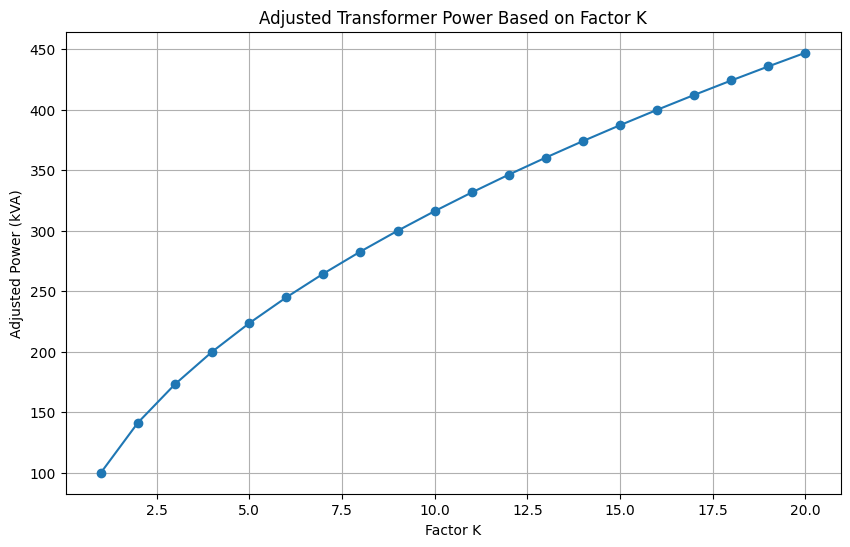

In [9]:

import matplotlib.pyplot as plt

# Define a range of K factors to analyze
k_factors = np.arange(1, 21)  # From K=1 to K=20

# Calculate the adjusted power for each K factor
adjusted_powers = [nominal_power * np.sqrt(1 + (k - 1)) for k in k_factors]

# Plot the results
plt.figure(figsize=(10, 6))
plt.plot(k_factors, adjusted_powers, marker='o')
plt.title("Adjusted Transformer Power Based on Factor K")
plt.xlabel("Factor K")
plt.ylabel("Adjusted Power (kVA)")
plt.grid(True)
plt.show()



## Conclusão

O fator K é uma métrica essencial para o dimensionamento de transformadores em sistemas onde há presença de harmônicos, como em cargas não lineares. Um transformador dimensionado corretamente para um fator K específico pode operar com maior confiabilidade e durabilidade, evitando problemas de superaquecimento e falhas precoces.

Este exemplo mostrou como calcular o fator K e utilizá-lo para ajustar a potência nominal de um transformador. Em aplicações reais, o fator K ajuda a garantir que o transformador suportará as condições de operação esperadas.
